In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd


In [2]:
# ---
# Installed capacity in 2025
# ---

capacity_2025 = {
    # IRENA Renewable Capacity Highlights 2026 reports end-2025
    # renewable installed capacity by technology:
    # Solar = 2,392 GW
    # Wind = 1,291 GW
    # Renewable hydropower = 1,296 GW
    # Bioenergy = 154 GW
    # Geothermal = 16 GW
    # Marine = 0.5 GW
    #
    # Source:
    # IRENA (2026), Renewable Capacity Highlights 2026.
    # https://www.irena.org/-/media/Files/IRENA/Agency/Publication/2026/Mar/IRENA_DAT_RE_capacity_highlights_2026.pdf
    "Solar": 2392,
    "Wind": 1291,
    "Hydropower": 1296,
    "Bioenergy": 154,
    "Geothermal": 16,
    "Tidal/Wave": 0.5,

    # IAEA reported 376.3 GW(e) of operating nuclear capacity
    # as of 19 November 2025.
    #
    # Source:
    # IAEA (2025), Six global trends in nuclear power you should know.
    # https://www.iaea.org/newscenter/news/six-global-trends-in-nuclear-power-you-should-know
    "Nuclear": 376.3,

    # Global Energy Monitor / Reuters reported 2,143 GW of global
    # coal power capacity at the end of 2024.
    #
    # The previous figure used this as the closest available observed
    # value for the 2025 panel. Replace with a full GEM 2025 value
    # if you later download the Global Coal Plant Tracker.
    #
    # Source:
    # Reuters based on Global Energy Monitor data, 2025.
    # https://www.reuters.com/business/energy/global-coal-power-capacity-inches-up-2024-data-shows-2025-04-03/
    "Coal": 2143,

    # Residual estimate for gas, oil and other non-renewable thermal.
    #
    # IRENA reports total renewable capacity = 5,149 GW, representing
    # 49.4% of total global installed power capacity in 2025.
    #
    # Therefore:
    # total global capacity ≈ 5,149 / 0.494 = 10,423 GW
    #
    # Residual thermal capacity =
    # total global capacity
    # - renewables
    # - nuclear
    # - coal
    #
    # = 10,423 - 5,149 - 376.3 - 2,143
    # ≈ 2,755 GW
    #
    # This category combines natural gas and oil.
    # https://globalenergymonitor.org/projects/global-oil-gas-plant-tracker?popup=2638
    "Natural Gas/Oil": 2205,
}


# ---
# Scenario capacity in 2050
# ---

capacity_2050 = {
    # Source:
    # IRENA / WMO (2025), Renewable Energy Statistics / pathway summary.
    # https://www.irena.org/-/media/Files/IRENA/Agency/Publication/2026/Jan/IRENA_WMO_PAR_Year-in-review_2024_2025.pdf
    #
    # The values are commonly reported in IRENA 1.5°C-aligned
    # deployment discussions.
    "Solar": 18200,
    "Wind": 7800,
    "Hydropower": 2500,

    # IRENA reports that bioenergy installed capacity would increase
    # from 108 GW in 2017 to 685 GW in 2050.
    #
    # Source:
    # IRENA (2020), Recycle: Bioenergy.
    # Circular Carbon Economy report.
    # https://www.irena.org/-/media/Files/IRENA/Agency/Publication/2020/Sep/CC_05_Recycle_bioenergy_2020.pdf
    "Bioenergy": 685,

    # IEA Technology Roadmap for Geothermal Heat and Power indicates
    # that geothermal electricity capacity could reach 200 GW by 2050.
    #
    # Source:
    # IEA (2011), Technology Roadmap: Geothermal Heat and Power.
    # https://www.iea.org/reports/technology-roadmap-geothermal-heat-and-power
    "Geothermal": 200,

    # IRENA reports that ocean energy could reach more than 350 GW
    # of cumulative installed capacity by 2050.
    #
    # Source:
    # IRENA (2021), Offshore Renewables: An Action Agenda for Deployment.
    # https://www.irena.org/-/media/Files/IRENA/Agency/Publication/2021/Jul/IRENA_G20_Offshore_renewables_2021.pdf
    "Tidal/Wave": 350,

    # IAEA 2050 nuclear projection range:
    # Low case = 561 GW(e)
    # High case = 992 GW(e)
    #
    # The 750 GW value is an approximate central value within that range,
    # not a specific IAEA scenario result.
    #
    # Source:
    # IAEA nuclear power projections.
    # https://www.iaea.org/newscenter/pressreleases/iaea-raises-nuclear-power-projections-for-fifth-consecutive-year
    "Nuclear": 750,

    # Assumption for a net-zero-aligned scenario:
    # unabated coal power is assumed to be phased out by 2050.
    #
    # Source basis:
    # IEA Net Zero by 2050 scenario states that unabated coal power
    # is phased out or retrofitted in advanced economies by 2030 and
    # globally by 2040.
    #
    # Source:
    # IEA (2021), Net Zero by 2050.
    # https://www.iea.org/reports/net-zero-by-2050
    "Coal": 0,

    # Assumption / placeholder:
    # Residual gas, oil and other thermal capacity in 2050.
    #
    # This value was not taken directly from a single source.
    # It represents residual flexible thermal / low-carbon thermal /
    # other dispatchable capacity in the scenario.
    "Natural Gas/Oil": 500,
}


In [3]:
# ---
# Build plotting dataframe
# ---

df = (
    pd.DataFrame(
        {
            "2025": capacity_2025,
            "2050": capacity_2050,
        }
    )
    .rename_axis("Technology")
    .reset_index()
)


# ---
# Palette
# ---

palette = {
    "Solar": "#FDBF11",  # Solar yellow
    "Wind": "#0099C6",  # Wind blue
    "Hydropower": "#3366CC",  # Hydro blue
    "Bioenergy": "#109618",  # Biomass green
    "Geothermal": "#66AA00",  # Geothermal green
    "Tidal/Wave": "#22AA99",  # Ocean teal
    "Nuclear": "#990099",  # Nuclear purple
    "Coal": "#444444",  # Coal dark grey
    "Natural Gas/Oil": "#D73027",  # Red
}


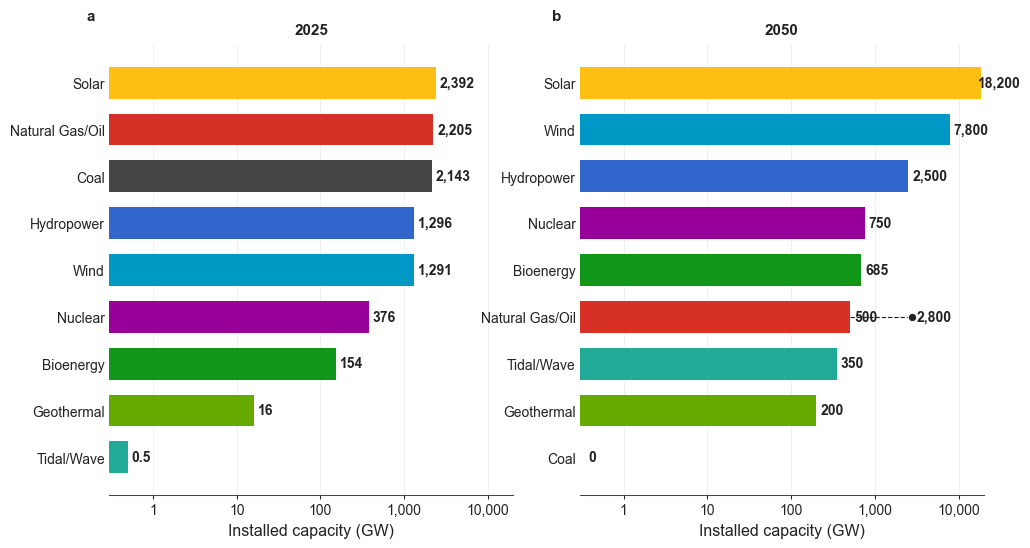

In [4]:
# ---
# Installed capacity by technology in 2025 and 2050
# ---

# Technologies are ordered independently by capacity within each panel.
# The existing colour scheme is retained through `palette`.


# ---
# Configuration
# ---

technology_col = "Technology"

years_to_plot = [
    "2025",
    "2050",
]

panel_labels = [
    "a",
    "b",
]

# Log-scale plotting range
X_MIN = 0.3
X_MAX = 20000
USE_LOG_SCALE = True

# Alternative 2050 gas/oil/thermal case
ALT_TECH = "Natural Gas/Oil"
ALT_YEAR = "2050"
ALT_VALUE = 2800


# ---
# Prepare data
# ---

df_plot_base = df.copy()

for year in years_to_plot:
    df_plot_base[year] = pd.to_numeric(
        df_plot_base[year],
        errors="coerce",
    )

df_plot_base = df_plot_base.dropna(
    subset=[technology_col],
).copy()


# ---
# Style
# ---

FONT_BASE = 10.0
FONT_TICKS = 10.0
FONT_TITLE = 11.0
FONT_PANEL = 11.0
FONT_AXIS_LABEL = 11.5
FONT_VALUE = 10.0

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


# ---
# Colours
# ---

TEXT_COLOUR = "#222222"
AXIS_COLOUR = "#444444"
GRID_COLOUR = "#BFBFBF"
ALT_COLOUR = TEXT_COLOUR
COLOR_BACKGROUND = "white"


# ---
# Helper functions
# ---

# Format installed-capacity values for bar labels.
def format_capacity_label(value):
    if pd.isna(value):
        return ""

    if value <= 0:
        return "0"

    if value < 10:
        return f"{value:.1f}"

    return f"{value:,.0f}"


# Return the plotting colour for a technology.
def get_technology_colour(tech):
    return palette.get(
        tech,
        "#CCCCCC",
    )


# Return left position and width for a log-scale horizontal bar.
def get_bar_left_and_width(value):
    if pd.isna(value) or value <= 0:
        return X_MIN, 0

    value_clipped = max(
        value,
        X_MIN,
    )

    return X_MIN, value_clipped - X_MIN


# Return the x position used for bar-end labels.
def get_label_x_position(value):
    if pd.isna(value) or value <= 0:
        return X_MIN * 1.25

    if USE_LOG_SCALE:
        return min(
            value * 1.12,
            X_MAX / 1.18,
        )

    return min(
        value * 1.02,
        X_MAX / 1.18,
    )


# ---
# Figure
# ---

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(10.8, 5.8),
)

fig.patch.set_facecolor(
    COLOR_BACKGROUND,
)


# ---
# Plot panels
# ---

for ax, year, panel_label in zip(
    axes,
    years_to_plot,
    panel_labels,
):
    ax.set_facecolor(
        COLOR_BACKGROUND,
    )

    # Sort independently by size in each panel
    df_panel = (
        df_plot_base
        .sort_values(
            year,
            ascending=False,
        )
        .reset_index(drop=True)
    )

    technologies = df_panel[
        technology_col
    ].to_numpy()

    values = (
        df_panel[year]
        .fillna(0)
        .to_numpy(dtype=float)
    )

    y_positions = np.arange(
        len(df_panel),
    )

    bar_colours = [
        get_technology_colour(tech)
        for tech in technologies
    ]

    # Bars
    for y_pos, value, colour in zip(
        y_positions,
        values,
        bar_colours,
    ):
        if USE_LOG_SCALE:
            left, width = get_bar_left_and_width(
                value,
            )

            ax.barh(
                y_pos,
                width,
                left=left,
                color=colour,
                edgecolor="none",
                height=0.68,
                zorder=3,
            )
        else:
            ax.barh(
                y_pos,
                value,
                color=colour,
                edgecolor="none",
                height=0.68,
                zorder=3,
            )

    # Alternative 2050 case
    if year == ALT_YEAR and ALT_TECH in technologies:
        y_alt = np.where(
            technologies == ALT_TECH,
        )[0][0]

        main_value = values[y_alt]
        alt_start = max(
            main_value,
            X_MIN,
        )

        ax.plot(
            [
                alt_start,
                ALT_VALUE,
            ],
            [
                y_alt,
                y_alt,
            ],
            color=ALT_COLOUR,
            linewidth=0.85,
            linestyle="--",
            zorder=4,
        )

        ax.scatter(
            ALT_VALUE,
            y_alt,
            s=36,
            color=ALT_COLOUR,
            edgecolor="white",
            linewidth=0.70,
            zorder=5,
        )

        ax.text(
            min(
                ALT_VALUE * 1.12,
                X_MAX / 1.18,
            ),
            y_alt,
            f"{ALT_VALUE:,.0f}",
            va="center",
            ha="left",
            fontsize=FONT_VALUE,
            fontweight="bold",
            color=TEXT_COLOUR,
            zorder=6,
        )

    # Value labels
    for y_pos, value in zip(
        y_positions,
        values,
    ):
        ax.text(
            get_label_x_position(value),
            y_pos,
            format_capacity_label(value),
            va="center",
            ha="left",
            fontsize=FONT_VALUE,
            fontweight="bold",
            color=TEXT_COLOUR,
            zorder=6,
        )

    # X axis
    if USE_LOG_SCALE:
        ax.set_xscale(
            "log",
        )

        ax.set_xlim(
            X_MIN,
            X_MAX,
        )

        ax.set_xticks(
            [
                1,
                10,
                100,
                1000,
                10000,
            ]
        )

        ax.xaxis.set_major_formatter(
            mticker.FuncFormatter(
                lambda x, pos: f"{x:,.0f}",
            )
        )

        ax.xaxis.set_minor_locator(
            mticker.NullLocator(),
        )
    else:
        ax.set_xlim(
            0,
            X_MAX,
        )

    # Y axis
    ax.set_ylim(
        -0.8,
        len(technologies) - 0.2,
    )

    ax.set_yticks(
        y_positions,
    )

    ax.set_yticklabels(
        technologies,
        fontsize=FONT_TICKS,
        color=TEXT_COLOUR,
    )

    # Largest capacity at the top
    ax.invert_yaxis()

    ax.set_xlabel(
        "Installed capacity (GW)",
        fontsize=FONT_AXIS_LABEL,
        fontweight="normal",
        color=TEXT_COLOUR,
    )

    ax.set_title(
        year,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=8,
        color=TEXT_COLOUR,
    )

    # Panel label
    panel_x = (
        -0.055
        if panel_label == "a"
        else -0.070
    )

    ax.text(
        panel_x,
        1.08,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    # Grid and spines
    ax.grid(
        axis="x",
        color=GRID_COLOUR,
        linewidth=0.45,
        alpha=0.35,
        zorder=0,
    )

    ax.grid(
        axis="y",
        visible=False,
    )

    ax.set_axisbelow(
        True,
    )

    for spine in [
        "top",
        "right",
        "left",
    ]:
        ax.spines[spine].set_visible(
            False,
        )

    ax.spines["bottom"].set_linewidth(
        0.75,
    )

    ax.spines["bottom"].set_color(
        AXIS_COLOUR,
    )

    ax.tick_params(
        axis="x",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
    )

    ax.tick_params(
        axis="y",
        length=0,
        pad=3,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
        labelleft=True,
    )


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.185,
    right=0.995,
    bottom=0.145,
    top=0.920,
    wspace=0.165,
)


# ---
# Save
# ---

plt.savefig(
    "figures/si/figure-1.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)
plt.savefig(
    "figures/si/figure-1.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.show()
